# Iris Flower Classification

## CodeAlpha Data Science Internship

### Objective
Build a machine learning classification model to predict the species of an Iris flower using its sepal and petal measurements.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
iris = load_iris()



In [3]:
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df["species"] = iris.target

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 150
Columns: 5


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [6]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [7]:
df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

In [8]:
df["species_name"] = df["species"].map({
    0: "setosa",
    1: "versicolor",
    2: "virginica"
})

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,species_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [9]:
df["species_name"].value_counts()

species_name
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

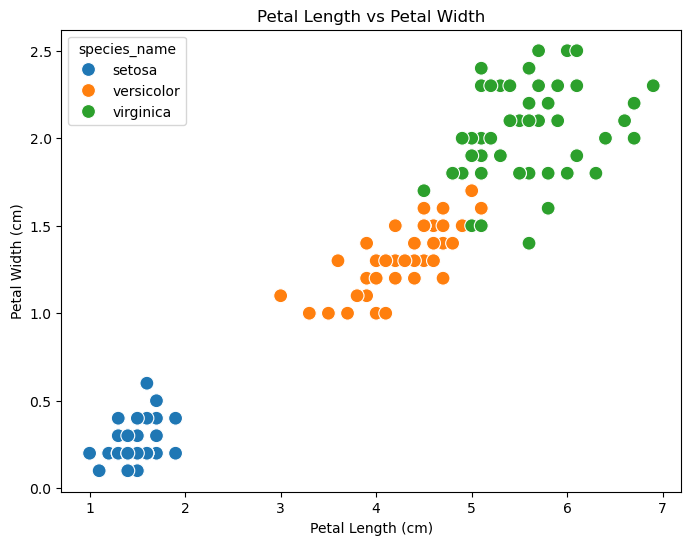

In [10]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="species_name",
    s=100
)

plt.title("Petal Length vs Petal Width")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.show()

In [11]:
X = df[[
    "sepal length (cm)",
    "sepal width (cm)",
    "petal length (cm)",
    "petal width (cm)"
]]

y = df["species"]

In [12]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (150, 4)
y shape: (150,)


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [14]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (120, 4)
Testing features: (30, 4)
Training target: (120,)
Testing target: (30,)


In [15]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [16]:
model = LogisticRegression(max_iter=200)

In [17]:
model.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,200
,multi_class,'deprecated'


In [18]:
y_pred = model.predict(X_test_scaled)

In [19]:
print(y_pred)

[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]


In [20]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

comparison


,Actual,Predicted
0,0,0
1,2,2
2,1,1
3,1,1
4,0,0
5,1,1
6,0,0
7,0,0
8,2,2
9,1,1


In [21]:
accuracy = accuracy_score(y_test, y_pred)

In [24]:
print(f"Accuracy: {accuracy * 100:.2f}%")


Accuracy: 93.33%


In [25]:
y_pred = model.predict(X_test_scaled)

In [26]:
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


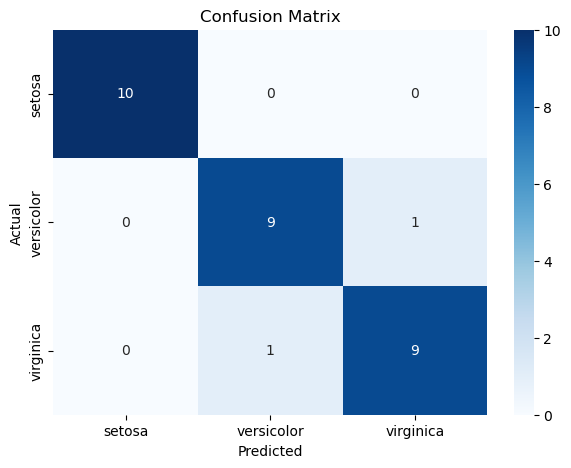

In [27]:
cm = confusion_matrix(y_test, y_pred)

print(cm)


plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [30]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)


In [31]:
knn.fit(X_train_scaled, y_train)
knn_pred = knn.predict(X_test_scaled)


In [32]:
knn_accuracy = accuracy_score(y_test, knn_pred)

print(f"KNN Accuracy: {knn_accuracy * 100:.2f}%")

KNN Accuracy: 93.33%


In [33]:
from sklearn.ensemble import RandomForestClassifier


In [34]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [35]:
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

In [36]:
rf_accuracy = accuracy_score(y_test, rf_pred)

print(f"Random Forest Accuracy: {rf_accuracy * 100:.2f}%")

Random Forest Accuracy: 90.00%


In [37]:
print(f"Logistic Regression: {accuracy * 100:.2f}%")
print(f"KNN:                {knn_accuracy * 100:.2f}%")
print(f"Random Forest:      {rf_accuracy * 100:.2f}%")

Logistic Regression: 93.33%
KNN:                93.33%
Random Forest:      90.00%


In [38]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy,
        knn_accuracy,
        rf_accuracy
    ]
})

results

,Model,Accuracy
0,Logistic Regression,0.933333
1,KNN,0.933333
2,Random Forest,0.900000


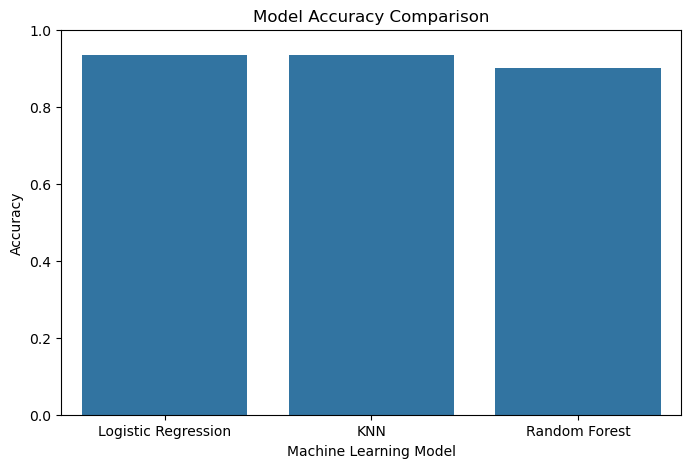

In [39]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy"
)

plt.ylim(0, 1)
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Machine Learning Model")
plt.show()

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



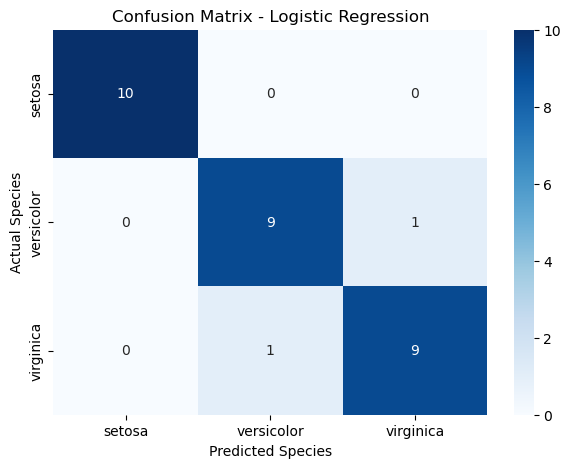

In [41]:
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))


cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Confusion Matrix - Logistic Regression")

plt.show()



In [42]:
results_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

results_df


incorrect = results_df[
    results_df["Actual"] != results_df["Predicted"]
]

incorrect

,Actual,Predicted
23,2,1
25,1,2


In [43]:
results_df["Actual Species"] = results_df["Actual"].map({
    0: "Setosa",
    1: "Versicolor",
    2: "Virginica"
})

results_df["Predicted Species"] = results_df["Predicted"].map({
    0: "Setosa",
    1: "Versicolor",
    2: "Virginica"
})

incorrect = results_df[
    results_df["Actual"] != results_df["Predicted"]
]

incorrect[["Actual Species", "Predicted Species"]]

,Actual Species,Predicted Species
23,Virginica,Versicolor
25,Versicolor,Virginica


In [44]:
import joblib


joblib.dump(model, "iris_logistic_regression_model.pkl")


joblib.dump(scaler, "iris_scaler.pkl")

['iris_scaler.pkl']

In [46]:
loaded_model = joblib.load(
    "iris_logistic_regression_model.pkl"
)

loaded_scaler = joblib.load(
    "iris_scaler.pkl"
)


new_flower = [[
    5.1,
    3.5,
    1.4,
    0.2
]]

In [47]:
new_flower_scaled = loaded_scaler.transform(new_flower)


prediction = loaded_model.predict(new_flower_scaled)


predicted_species = iris.target_names[prediction[0]]

print("Predicted species:", predicted_species)

Predicted species: setosa


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
